In [3]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

file_path = (
    "/content/drive/MyDrive/"
    "ChampionsAthleticMap/data/raw/megaGymDataset.csv"
)

gym_df = pd.read_csv(file_path)

print("Dataset shape:", gym_df.shape)
display(gym_df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/ChampionsAthleticMap/data/raw/megaGymDataset.csv'

***Exploratory Data Analysis***

In [ ]:
#Dataset Structure
gym_df.info()
print("\n")

#missing values
print("Missing Values:", gym_df.isna().sum(),"\n")

#duplicate records
print("Duplicate rows:", gym_df.duplicated().sum(), "\n")

#exercise records
print("Types of Exercises: ", gym_df['Type'].unique(), "\n")

#exercise difficulty level
print("Exercise Difficulty Level: ", gym_df['Level'].unique())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2918 entries, 0 to 2917
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  2918 non-null   int64  
 1   Title       2918 non-null   object 
 2   Desc        1368 non-null   object 
 3   Type        2918 non-null   object 
 4   BodyPart    2918 non-null   object 
 5   Equipment   2886 non-null   object 
 6   Level       2918 non-null   object 
 7   Rating      1031 non-null   float64
 8   RatingDesc  862 non-null    object 
dtypes: float64(1), int64(1), object(7)
memory usage: 205.3+ KB


Missing Values: Unnamed: 0       0
Title            0
Desc          1550
Type             0
BodyPart         0
Equipment       32
Level            0
Rating        1887
RatingDesc    2056
dtype: int64 

Duplicate rows: 0 

Types of Exercises:  ['Strength' 'Plyometrics' 'Cardio' 'Stretching' 'Powerlifting' 'Strongman'
 'Olympic Weightlifting'] 

Exercise Difficulty Level:  ['I

#Perform detailed EDA

In [ ]:
#Analyze missing values

missing_report = pd.DataFrame({
    "Missing_Count": gym_df.isnull().sum(),
    "Missing_Percentage": (
        gym_df.isnull().mean() * 100
    ).round(2)
})

display(missing_report)

,Missing_Count,Missing_Percentage
Unnamed: 0,0,0.00
Title,0,0.00
Desc,1550,53.12
Type,0,0.00
BodyPart,0,0.00
Equipment,32,1.10
Level,0,0.00
Rating,1887,64.67
RatingDesc,2056,70.46


Check Duplicates

In [ ]:
print("Exact duplicate rows:", gym_df.duplicated().sum())

print("Duplicate exercise titles:",gym_df["Title"].duplicated().sum())

duplicate_titles = gym_df[gym_df.duplicated(subset=["Title"], keep=False)]

display(duplicate_titles.sort_values("Title").head(20))

Exact duplicate rows: 0
Duplicate exercise titles: 9


,Unnamed: 0,Title,Desc,Type,BodyPart,Equipment,Level,Rating,RatingDesc
2540,2540,Arnold press,Named after the iconic bodybuilder and movie s...,Strength,Shoulders,Dumbbell,Intermediate,8.9,Average
2655,2655,Arnold press,Named after the iconic bodybuilder and movie s...,Strength,Shoulders,Dumbbell,Intermediate,8.9,Average
919,919,Band-suspended kettlebell bench press,The band-suspended kettlebell bench press is a...,Strength,Chest,Bands,Intermediate,NaN,NaN
939,939,Band-suspended kettlebell bench press,The band-suspended kettlebell bench press is a...,Strength,Chest,Bands,Intermediate,NaN,NaN
958,958,Band-suspended kettlebell bench press,The band-suspended kettlebell bench press is a...,Strength,Chest,Bands,Intermediate,NaN,NaN
10,10,Decline bar press sit-up,The decline bar press sit-up is a weighted cor...,Strength,Abdominals,Barbell,Intermediate,8.5,Average
97,97,Decline bar press sit-up,The decline bar press sit-up is a weighted cor...,Strength,Abdominals,Barbell,Intermediate,8.5,Average
1922,1922,Dumbbell step-up,The dumbbell step-up is a great exercise for b...,Strength,Quadriceps,Dumbbell,Intermediate,8.2,Average
2004,2004,Dumbbell step-up,The dumbbell step-up is a great exercise for b...,Strength,Quadriceps,Dumbbell,Intermediate,8.2,Average
163,163,Exercise Ball Cable Crunch - Gethin Variation,The exercise ball crunch is a popular gym exer...,Strength,Abdominals,Cable,Intermediate,NaN,NaN


EXPLORE EXERCISE CATEGORIES

In [ ]:
categorical_columns = [
    "Type",
    "BodyPart",
    "Equipment",
    "Level"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    display(gym_df[col].value_counts(dropna=False))


--- Type ---


,count
Type,
Strength,2545
Stretching,147
Plyometrics,97
Powerlifting,37
Cardio,35
Olympic Weightlifting,35
Strongman,22



--- BodyPart ---


,count
BodyPart,
Abdominals,662
Quadriceps,646
Shoulders,340
Chest,262
Biceps,168
Triceps,151
Lats,124
Hamstrings,121
Middle Back,118



--- Equipment ---


,count
Equipment,
Body Only,1078
Dumbbell,516
Barbell,282
Other,254
Cable,226
Machine,175
Kettlebells,149
Bands,100
Medicine Ball,38



--- Level ---


,count
Level,
Intermediate,2446
Beginner,459
Expert,13


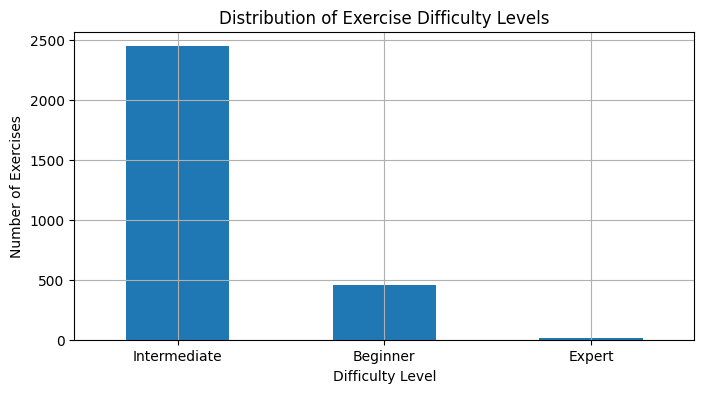

In [ ]:
import matplotlib.pyplot as plt

gym_df["Level"].value_counts().plot(
    kind="bar",
    figsize=(8, 4)
)

plt.title("Distribution of Exercise Difficulty Levels")
plt.xlabel("Difficulty Level")
plt.ylabel("Number of Exercises")
plt.xticks(rotation=0)
plt.grid(True)
plt.show()

Investigate missing exercise descriptions

In [ ]:
missing_desc = gym_df[gym_df["Desc"].isnull()]

display(
    missing_desc[
        ["Title", "Type", "BodyPart", "Equipment", "Level"]
    ].head(20)
)

,Title,Type,BodyPart,Equipment,Level
6,FYR2 Banded Frog Pump,Strength,Abdominals,Bands,Intermediate
12,Barbell Side Bend,Strength,Abdominals,Barbell,Beginner
19,KV Barbell Hip Thrust,Strength,Abdominals,Barbell,Intermediate
20,Advanced Kettlebell Windmill,Strength,Abdominals,Kettlebells,Beginner
22,Kettlebell Pass Between The Legs,Strength,Abdominals,Kettlebells,Beginner
24,Double Kettlebell Swing,Strength,Abdominals,Kettlebells,Intermediate
30,Taylor Single-Arm Kettlebell Swing,Strength,Abdominals,Kettlebells,Intermediate
31,Holman Kettlebell Up to Elbow Down,Strength,Abdominals,Kettlebells,Intermediate
32,FYR2 Double-Kettlebell Ski,Strength,Abdominals,Kettlebells,Intermediate
33,FYR2 Kettlebell Hike,Strength,Abdominals,Kettlebells,Intermediate


In [ ]:
display(
    gym_df[gym_df["Desc"].notnull()][
        ["Title", "Desc", "Type", "Level"]
    ].head(10)
)

,Title,Desc,Type,Level
0,Partner plank band row,The partner plank band row is an abdominal exe...,Strength,Intermediate
1,Banded crunch isometric hold,The banded crunch isometric hold is an exercis...,Strength,Intermediate
2,FYR Banded Plank Jack,The banded plank jack is a variation on the pl...,Strength,Intermediate
3,Banded crunch,The banded crunch is an exercise targeting the...,Strength,Intermediate
4,Crunch,The crunch is a popular core exercise targetin...,Strength,Intermediate
5,Decline band press sit-up,The decline band press sit-up is a weighted co...,Strength,Intermediate
7,Band low-to-high twist,The band low-to-high twist is a core exercise ...,Strength,Intermediate
8,Barbell roll-out,The barbell roll-out is an abdominal exercise ...,Strength,Intermediate
9,Barbell Ab Rollout - On Knees,The barbell roll-out is an abdominal exercise ...,Strength,Intermediate
10,Decline bar press sit-up,The decline bar press sit-up is a weighted cor...,Strength,Intermediate
